# 04 training evaluation
Dataset-dependent analysis is pending. No dataset is loaded automatically.

In [1]:
from classification.plotting import save_figure
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import pandas as pd

import classification
from classification.model_config import MODEL_CONFIGS
from classification.training import create_models, create_cross_validation, compare_models, tune_model

## Baseline and evaluation metrics
Record observations and justify decisions here after selecting the dataset.

In [3]:
df = pd.read_csv("../data/raw/student_mental_health.csv")

In [4]:
from classification.model_config import RANDOM_STATE
from sklearn.model_selection import train_test_split
from classification.preprocessing import remove_invalid_targets

cleaned_df = remove_invalid_targets(df)
X = cleaned_df.drop(columns=["Student_ID", "Mental_Health_Risk"])

risk_codes = {"Low": 0, "Medium": 1, "High": 2}
y = cleaned_df["Mental_Health_Risk"].map(risk_codes)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)


models = create_models(MODEL_CONFIGS)
cv = create_cross_validation()
result = compare_models(models, X_train, y_train, cv)


In [5]:
display(result)

,model,mean_score,std_score,mean_fit_time
0,logistic_regression,0.757708,0.020192,0.066212
3,svc,0.721404,0.020486,0.058300
2,random_forest,0.684276,0.021928,0.221246
1,decision_tree,0.571389,0.007163,0.041597


In [13]:

best = result.iloc[0]["model"]
best_2 = result.iloc[1]["model"]
search_best_1 = tune_model(models[best], MODEL_CONFIGS[best]["search_space"],
                           X_train,
                           y_train,
                           cv,
                           method="grid")

search_best_2 = tune_model(models[best_2], MODEL_CONFIGS[best_2]["search_space"], X_train, y_train, cv, method="grid")

In [14]:
from pathlib import Path
import joblib

model_path = Path("../reports/models/champion.joblib")
model_path_2 = Path("../reports/models/champion2.joblib")
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(search_best_1.best_estimator_, model_path)
joblib.dump(search_best_2.best_estimator_, model_path_2)

/workspace/reports/models/champion.joblib


Accuracy: 0.7675
              precision    recall  f1-score   support

         Low      0.831     0.780     0.805       132
      Medium      0.645     0.674     0.659       132
        High      0.833     0.846     0.839       136

    accuracy                          0.767       400
   macro avg      0.770     0.767     0.768       400
weighted avg      0.770     0.767     0.769       400

Matrice de confusion (lignes=vrai, colonnes=prédit):


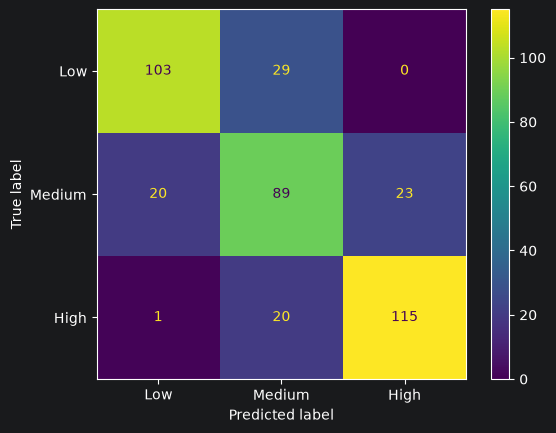

Accuracy: 0.745
              precision    recall  f1-score   support

         Low      0.820     0.758     0.787       132
      Medium      0.618     0.636     0.627       132
        High      0.803     0.838     0.820       136

    accuracy                          0.745       400
   macro avg      0.747     0.744     0.745       400
weighted avg      0.747     0.745     0.746       400

Matrice de confusion (lignes=vrai, colonnes=prédit):


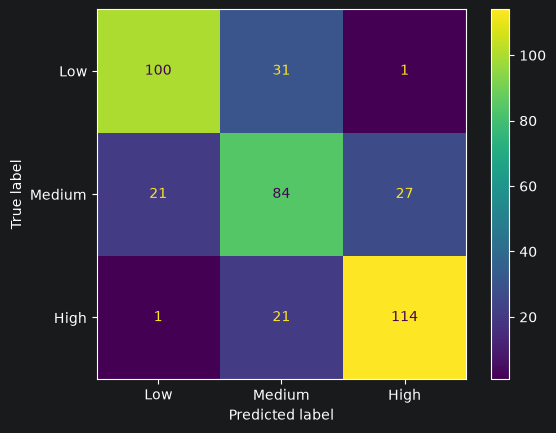

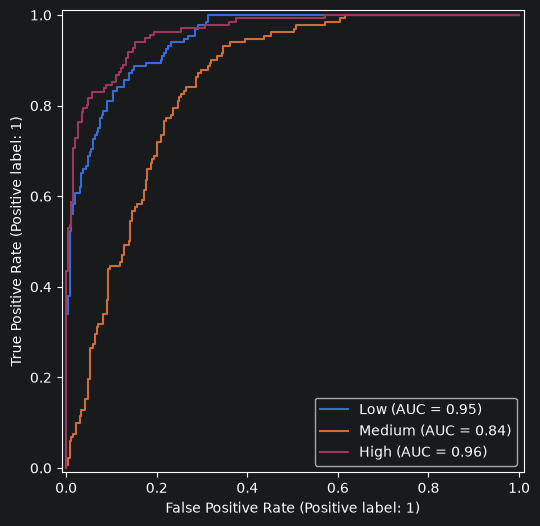

In [18]:
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay
from classification.plotting import save_figure

model = joblib.load(model_path)
model2 = joblib.load(model_path_2)
y_pred = model.predict(X_test)
y2_pred = model2.predict(X_test)
labels = [0, 1, 2]
names = ["Low", "Medium", "High"]

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, labels=labels, target_names=names, digits=3))
print("Matrice de confusion (lignes=vrai, colonnes=prédit):")
conf_matrix = confusion_matrix(y_test, y_pred, labels=labels)
ConfusionMatrixDisplay(confusion_matrix= conf_matrix, display_labels = names).plot()
plt.show()

print("Accuracy:", accuracy_score(y_test, y2_pred))
print(classification_report(y_test, y2_pred, labels=labels, target_names=names, digits=3))
print("Matrice de confusion (lignes=vrai, colonnes=prédit):")
conf_matrix = confusion_matrix(y_test, y2_pred, labels=labels)
ConfusionMatrixDisplay(confusion_matrix= conf_matrix, display_labels = names).plot()
plt.show()






proba = model.predict_proba(X_test)
fig, ax = plt.subplots(figsize=(7, 6))
for label, name in zip(labels, names):
    RocCurveDisplay.from_predictions(
        y_test == label,
        proba[:, label],
        name= name,
        ax=ax
    )
save_figure(fig, "roc_auc_graph")
plt.show()



we can see that the model with the best result is Logistic regression according to F1 score , in both steps first experiment and after tuning the best two models ( ll, svc ) , but we dont have a good result f1 = 0.768 , the problem is within the medium class , according to the confusiong matrix we had a 84 true prediction from 132 on test data   , therefor its f1 score = 0.62 also its auc = 0.84  which represent the area of medium